# Практическая работа № 6. Классификация текстов

ФИО: Кашымбеков Актан Ийгиликович.

Уровень C.

## Цель работы

Построить классификатор тематик новостей на кыргызском языке,
реализовать предобработку текста и сравнить два алгоритма
на одинаковом векторизованном представлении.

## Источник данных и разметка

Использован открытый корпус Kyrgyz Multi-Label Topic Classification:
https://github.com/alexeyev/kyrgyz-multi-label-topic-classification

Корпус содержит новости портала 24.kg на кыргызском языке.
Процедура разметки описана авторами:
https://arxiv.org/pdf/2308.15952

Используется готовая тематическая разметка авторов корпуса.
Самостоятельная разметка в этой работе не проводилась.

В исходном корпусе одна новость может иметь несколько тематических меток.
Для данной учебной работы задача ограничена классификацией новостей
с одной меткой. Записи с несколькими метками исключаются целиком:
выбор первой метки не выполняется.

Также исключаются пустые тексты, дубликаты и классы,
в которых после подготовки осталось меньше 20 документов.
Это ограничение позволяет оценивать классы с достаточным числом примеров.

Задача: по тексту новости предсказать её тематический класс.
Полученные результаты относятся к выбранной части корпуса.

In [ ]:
from pathlib import Path
import re
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42

In [ ]:
project_dirs = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "ml-social-media-sleep"]

PROJECT_DIR = next(
    (
        folder
        for folder in project_dirs
        if (folder / "practice6" / "data" / "qad-train_1000.csv").is_file()
        and (folder / "practice6" / "data" / "qad-test_0500.csv").is_file()
    ),
    None,
)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Не найдены CSV. Проверь, что оба файла лежат в practice6/data."
    )

DATA_DIR = PROJECT_DIR / "practice6" / "data"

source_train = pd.read_csv(DATA_DIR / "qad-train_1000.csv")
source_test = pd.read_csv(DATA_DIR / "qad-test_0500.csv")

raw = pd.concat(
    [source_train, source_test],
    ignore_index=True,
)

print("Первый файл:", source_train.shape)
print("Второй файл:", source_test.shape)
print("Общий корпус:", raw.shape)

display(raw.head(3))
display(raw.isna().sum().rename("Пропуски"))

Первый файл: (1000, 4)
Второй файл: (500, 4)
Общий корпус: (1500, 4)


,id,text,labels_set,tokenized_text
0,22077,«Байсуу» кафесинин жайкы аянтчасына бастырма к...,"development,local announcements",« Байсуу » кафесинин жайкы аянтчасына бастырма...
1,4575,Жер ресуртары боюнча мамлекеттик агенттиги түз...,"development,natural resources",Жер ресуртары боюнча мамлекеттик агенттиги түз...
2,14332,«Өзгөн» мамлекеттик тарыхый-маданий музей-кору...,"culture,local announcements",« Өзгөн » мамлекеттик тарыхый - маданий музей ...


id                 0
text               0
labels_set         0
tokenized_text    23
Name: Пропуски, dtype: int64

Исходные файлы объединены для формирования собственной учебной выборки.
После очистки и удаления дубликатов будет создано новое разбиение train/test.

Оригинальное разбиение авторов не используется, поэтому результаты
этой работы нельзя напрямую сравнивать с результатами исходного benchmark.

In [ ]:
df = raw.copy()

df["text"] = df["text"].fillna("").astype(str)
df["labels_set"] = (
    df["labels_set"]
    .fillna("")
    .astype(str)
    .str.strip()
)

preparation_log = [{"Этап": "Исходный корпус", "Документов": len(df)}]

df = df[
    df["text"].str.strip().ne("")
    & df["labels_set"].ne("")
].copy()

preparation_log.append({
    "Этап": "Без пустых текстов и меток",
    "Документов": len(df),
})

df["labels"] = df["labels_set"].apply(
    lambda value: [
        label.strip()
        for label in value.split(",")
        if label.strip()
    ]
)

df = df[df["labels"].map(len).eq(1)].copy()
df["label"] = df["labels"].map(lambda labels: labels[0])

preparation_log.append({
    "Этап": "Только одна тема на новость",
    "Документов": len(df),
})

def make_text_key(text):
    text = unicodedata.normalize("NFKC", text).lower()
    return " ".join(text.split())

df["text_key"] = df["text"].map(make_text_key)

labels_per_text = df.groupby("text_key")["label"].nunique()
conflicting_keys = labels_per_text[
    labels_per_text.gt(1)
].index

print("Текстов с противоречивыми метками:", len(conflicting_keys))

df = df[~df["text_key"].isin(conflicting_keys)].copy()

df = df.drop_duplicates(subset="text_key").copy()

preparation_log.append({
    "Этап": "Без конфликтов и нормализованных дубликатов",
    "Документов": len(df),
})

MIN_CLASS_SIZE = 20

class_counts = df["label"].value_counts()
selected_classes = class_counts[
    class_counts.ge(MIN_CLASS_SIZE)
].index

df = df[df["label"].isin(selected_classes)].copy()
df = df.reset_index(drop=True)

preparation_log.append({
    "Этап": "Классы с минимум 20 документами",
    "Документов": len(df),
})

display(pd.DataFrame(preparation_log))
display(df["label"].value_counts().rename("Документов"))

print("Итоговое число документов:", len(df))
print("Итоговое число классов:", df["label"].nunique())

assert len(df) >= 500, "После отбора осталось меньше 500 документов."

Текстов с противоречивыми метками: 0


,Этап,Документов
0,Исходный корпус,1500
1,Без пустых текстов и меток,1477
2,Только одна тема на новость,774
3,Без конфликтов и нормализованных дубликатов,753
4,Классы с минимум 20 документами,696


label
law and crime            173
politics                 136
health                   113
accidents                 80
local announcements       63
culture                   34
sports                    26
foreign affairs           25
society                   23
economics and finance     23
Name: Документов, dtype: int64

Итоговое число документов: 696
Итоговое число классов: 10


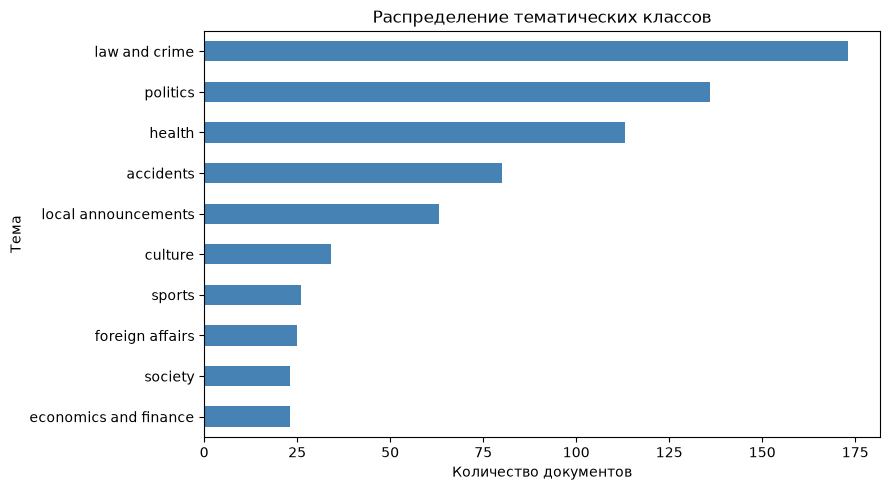

In [ ]:
counts = df["label"].value_counts()

ax = counts.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue",
)

ax.set_title("Распределение тематических классов")
ax.set_xlabel("Количество документов")
ax.set_ylabel("Тема")

plt.tight_layout()
plt.show()

Классы представлены неравномерно.
Наиболее многочисленные темы — law and crime, politics и health.

Поэтому качество будет оцениваться не только по accuracy,
но и по macro-F1: эта метрика учитывает каждый класс с одинаковым весом.

## Предобработка текста

Используются следующие шаги:

1. Нормализация Unicode.
2. Приведение к нижнему регистру.
3. Удаление URL.
4. Удаление цифр и пунктуации.
5. Токенизация — выделение отдельных слов.
6. Удаление стоп-слов из небольшого вручную составленного списка.

При обработке сохраняются кыргызские буквы ө, ү, ң.

Список стоп-слов зафиксирован до обучения и оценки моделей.
Это небольшой учебный список, а не полный словарь кыргызских стоп-слов.
Отрицания эмес и жок сохраняются, поскольку могут менять смысл текста.

Стемминг и лемматизация в этой работе не применяются.
Для базовой модели используются исходные словоформы.
Самодельное обрезание окончаний может повреждать слова.
Ограничение подхода: формы одного слова могут стать разными признаками.

In [ ]:
KY_STOP_WORDS = {
    "жана",
    "менен",
    "үчүн",
    "эле",
    "дагы",
    "же",
    "бирок",
    "ошондой",
    "боюнча",
    "катары",
    "тууралуу",
    "аркылуу",
    "чейин",
    "кийин",
}

assert "эмес" not in KY_STOP_WORDS
assert "жок" not in KY_STOP_WORDS

def tokenize_text(text):
    text = unicodedata.normalize("NFKC", str(text)).lower()

    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    return re.findall(r"[а-яёөүңa-z]+", text)

def clean_text(text):
    tokens = tokenize_text(text)

    filtered_tokens = [
        token
        for token in tokens
        if token not in KY_STOP_WORDS
    ]

    return " ".join(filtered_tokens)

df["clean_text"] = df["text"].map(clean_text)

empty_after_cleaning = df["clean_text"].str.strip().eq("")
print("Пустых текстов после очистки:", empty_after_cleaning.sum())

df = df.loc[~empty_after_cleaning].copy()
df = df.reset_index(drop=True)

print("Документов после предобработки:", len(df))

assert len(df) >= 500
assert df["label"].value_counts().min() >= 20

Пустых текстов после очистки: 0
Документов после предобработки: 696


In [ ]:
example = "Бишкек жана Ош: 2026-жылы маалымат жок!"

print("Учебный пример:", example)
print("Токены:", tokenize_text(example))
print("После очистки:", clean_text(example))

assert clean_text("Ө Ү Ң эмес жок") == "ө ү ң эмес жок"

for row in df.sample(3, random_state=RANDOM_STATE).itertuples():
    print("\n" + "=" * 70)
    print("ТЕМА:", row.label)
    print("\nИСХОДНЫЙ ТЕКСТ:")
    print(row.text[:700])
    print("\nПОСЛЕ ОЧИСТКИ:")
    print(row.clean_text[:700])

Учебный пример: Бишкек жана Ош: 2026-жылы маалымат жок!
Токены: ['бишкек', 'жана', 'ош', 'жылы', 'маалымат', 'жок']
После очистки: бишкек ош жылы маалымат жок

ТЕМА: health

ИСХОДНЫЙ ТЕКСТ:
Кыргызстанда коронавирус инфекциясын жуктургандардын саны 4,6 эсеге төмөндөдү. Бул тууралуу Улуттук статистика комитети маалымдайт.
КР Саламаттыкты сактоо министрлигинин маалыматы боюнча, үстүбүздөгү жылдын октябрында COVID-19дун катталган лабораториялык жана клиникалык-эпидемиологиялык тастыкталган учурларынын саны 2020-жылдын октябрындагы 13 миң учурдан ушул жылдын октябрь айында 2,9 миң учурга чейин азайды.
Ушул жылдын октябрында коронавирустук инфекциянын катталган учурларынын эң көп үлүшү Бишкек шаарына (51 пайыздан ашыгы), Чүй (26 пайыз) жана Ысык-Көл (12 пайызга жакын) облустарына туура келди.
Үстүбүздөгү жылдын октябрында калктын 100 миңине алганда оорулардын саны өткөн жылдын октябр

ПОСЛЕ ОЧИСТКИ:
кыргызстанда коронавирус инфекциясын жуктургандардын саны эсеге төмөндөдү бул улуттук статист

На примерах показано, что функция удаляет пунктуацию, цифры
и выбранные стоп-слова, сохраняя кыргызские буквы и отрицания.

Удаление цифр упрощает представление текста, но может терять информацию
о датах и количественных показателях, полезную для некоторых тем.

In [ ]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["label"],
)

train_df = train_df.copy()
test_df = test_df.copy()

print("Train:", len(train_df))
print("Test:", len(test_df))

overlap = set(train_df["text_key"]) & set(test_df["text_key"])

print("Совпадающих текстов между train и test:", len(overlap))
assert len(overlap) == 0

split_counts = pd.concat(
    [
        train_df["label"].value_counts().rename("train"),
        test_df["label"].value_counts().rename("test"),
    ],
    axis=1,
).fillna(0).astype(int)

display(split_counts)

Train: 556
Test: 140
Совпадающих текстов между train и test: 0


,train,test
label,,
law and crime,138,35
politics,109,27
health,90,23
accidents,64,16
local announcements,50,13
culture,27,7
sports,21,5
foreign affairs,20,5
society,19,4


Данные разделены на обучающую и тестовую части в отношении 80/20
с сохранением пропорций классов.

Обучающая часть используется для построения словаря TF-IDF
и обучения классификаторов. Тестовая часть используется для оценки.

In [ ]:
vectorizer = TfidfVectorizer(
    lowercase=False,
    tokenizer=str.split,
    token_pattern=None,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=15000,
)

X_train = vectorizer.fit_transform(train_df["clean_text"])
X_test = vectorizer.transform(test_df["clean_text"])

y_train = train_df["label"]
y_test = test_df["label"]

print("Матрица train:", X_train.shape)
print("Матрица test:", X_test.shape)
print("Размерность признакового пространства:", X_train.shape[1])

feature_names = vectorizer.get_feature_names_out()
print("Примеры признаков:", feature_names[:30])

zero_train = (X_train.getnnz(axis=1) == 0).sum()
zero_test = (X_test.getnnz(axis=1) == 0).sum()

print("Документов без признаков в train:", zero_train)
print("Документов без признаков в test:", zero_test)

Матрица train: (556, 6968)
Матрица test: (140, 6968)
Размерность признакового пространства: 6968
Примеры признаков: ['astrazeneca' 'covid' 'covid га' 'covid диагнозу' 'covid дун'
 'covid илдетинен' 'daewoo' 'daewoo nexia' 'hyundai' 'iii' 'in'
 'instagram' 'instagram публикация' 'kg' 'kg агентигине' 'kg агенттигине'
 'kg агенттигинин' 'kg маалымат' 'mercedes' 'moderna' 'nexia' 'no' 'pdt'
 'pfizer' 'pfizer moderna' 'sinopharm' 'ufc' 'v' 'v вакцинасын' 'youtube']
Документов без признаков в train: 0
Документов без признаков в test: 0


После TF-IDF-векторизации получена обучающая матрица размером
556 × 6968 и тестовая матрица размером 140 × 6968.

Размерность признакового пространства составляет 6968.
В признаки входят отдельные слова и пары соседних слов.

Словарь и веса IDF вычислены только по train.
Для test использован метод transform обученного векторизатора.
Это исключает обучение векторизатора на тестовых данных.

Документов с полностью нулевым вектором признаков
не обнаружено ни в train, ни в test.

## Сравнение классификаторов

Сравниваются:

- MultinomialNB — наивный байесовский классификатор;
- LogisticRegression — логистическая регрессия.

Оба алгоритма получают одинаковые TF-IDF-признаки
и оцениваются на одной тестовой выборке.

Дополнительно используется DummyClassifier:
он всегда предсказывает самый частый класс
и служит простой точкой отсчёта.

In [ ]:
models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "MultinomialNB": MultinomialNB(alpha=1.0),
    "LogisticRegression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
    ),
}

class_order = sorted(y_train.unique())

predictions = {}
result_rows = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)

    predictions[name] = predicted

    result_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Macro-F1": f1_score(
            y_test,
            predicted,
            labels=class_order,
            average="macro",
            zero_division=0,
        ),
        "Weighted-F1": f1_score(
            y_test,
            predicted,
            labels=class_order,
            average="weighted",
            zero_division=0,
        ),
    })

results = pd.DataFrame(result_rows).set_index("Модель")

display(results.round(4))

,Accuracy,Macro-F1,Weighted-F1
Модель,,,
Dummy,0.2500,0.0400,0.1000
MultinomialNB,0.5357,0.2600,0.4619
LogisticRegression,0.6000,0.3619,0.5532


In [ ]:
for name in ["MultinomialNB", "LogisticRegression"]:
    print("\n" + "=" * 70)
    print(name)

    print(
        classification_report(
            y_test,
            predictions[name],
            labels=class_order,
            digits=3,
            zero_division=0,
        )
    )


MultinomialNB
                       precision    recall  f1-score   support

            accidents      1.000     0.250     0.400        16
              culture      0.000     0.000     0.000         7
economics and finance      0.000     0.000     0.000         5
      foreign affairs      0.000     0.000     0.000         5
               health      0.950     0.826     0.884        23
        law and crime      0.397     0.886     0.549        35
  local announcements      1.000     0.077     0.143        13
             politics      0.541     0.741     0.625        27
              society      0.000     0.000     0.000         4
               sports      0.000     0.000     0.000         5

             accuracy                          0.536       140
            macro avg      0.389     0.278     0.260       140
         weighted avg      0.567     0.536     0.462       140


LogisticRegression
                       precision    recall  f1-score   support

            acci

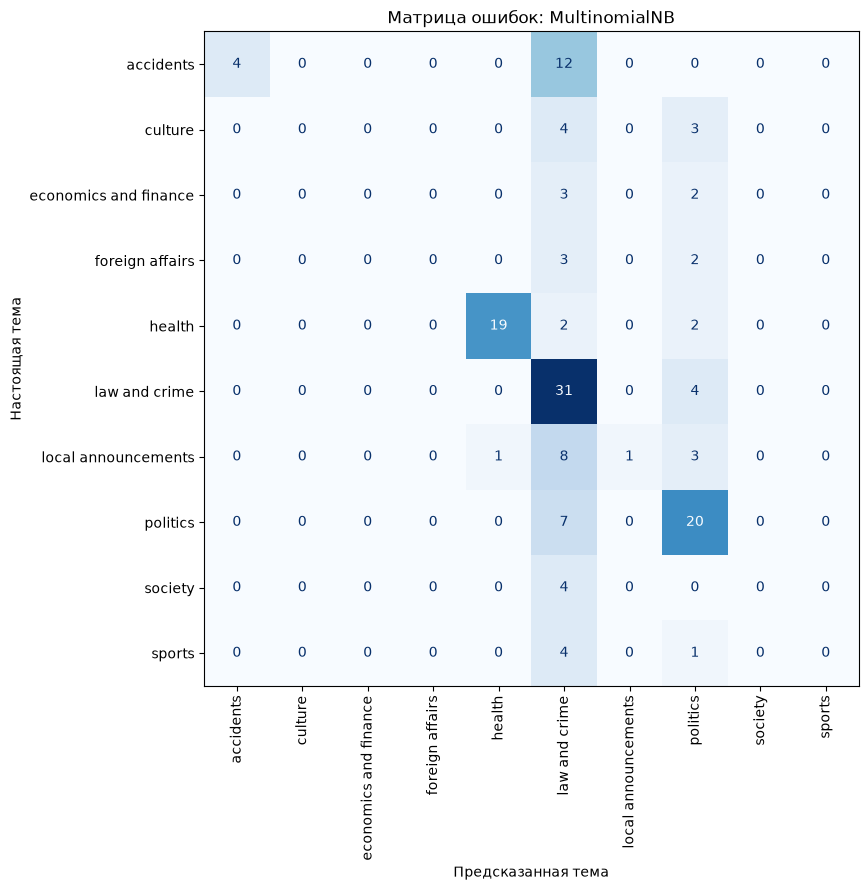

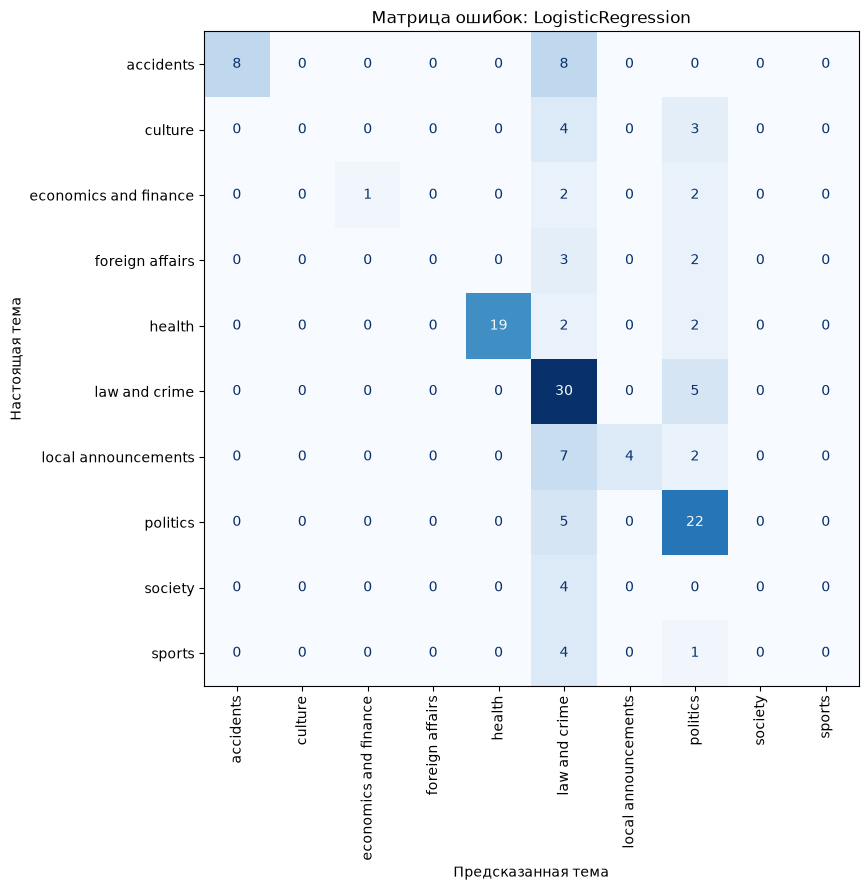

In [ ]:
for name in ["MultinomialNB", "LogisticRegression"]:
    fig, ax = plt.subplots(figsize=(11, 9))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[name],
        labels=class_order,
        display_labels=class_order,
        cmap="Blues",
        xticks_rotation=90,
        colorbar=False,
        ax=ax,
    )

    ax.set_title(f"Матрица ошибок: {name}")
    ax.set_xlabel("Предсказанная тема")
    ax.set_ylabel("Настоящая тема")

    plt.tight_layout()
    plt.show()

По macro-F1 лучше сработала LogisticRegression:
её результат составил 0.3619 против 0.2600 у MultinomialNB.

Accuracy логистической регрессии составила 0.6000,
а наивного байесовского классификатора — 0.5357.
Это соответствует 84 и 75 правильным ответам
из 140 тестовых документов.

Обе модели превзошли DummyClassifier,
который получил accuracy = 0.2500 и macro-F1 = 0.0400.

У LogisticRegression наиболее высокий F1 получен
для темы health — 0.905.
Для тем accidents и politics F1 составил приблизительно 0.667.

Самые низкие результаты получены для culture,
foreign affairs, society и sports: F1 равен 0.
Модель не предсказала ни одного документа этих четырёх классов.
Следовательно, accuracy = 0.6000 не означает,
что модель одинаково хорошо распознаёт все темы.

Матрица ошибок LogisticRegression показывает,
что 8 из 16 новостей accidents ошибочно отнесены к law and crime.
Также наблюдается взаимная путаница law and crime и politics:
по 5 ошибок в каждом направлении.

Возможные причины — пересечение тематической лексики
и неравномерное количество обучающих примеров.
Эти объяснения являются гипотезами.

In [ ]:
error_tables = {}

for name in ["MultinomialNB", "LogisticRegression"]:
    checked = test_df[
        ["id", "text", "clean_text", "label"]
    ].copy()

    checked["prediction"] = predictions[name]
    checked["correct"] = checked["label"].eq(checked["prediction"])

    errors = checked.loc[~checked["correct"]].copy()
    error_tables[name] = errors

    print("\n" + "=" * 70)
    print("МОДЕЛЬ:", name)
    print("Всего ошибок:", len(errors))

    if errors.empty:
        print("На этой тестовой выборке ошибок нет.")
        continue

    examples = errors.sample(
        n=min(3, len(errors)),
        random_state=RANDOM_STATE,
    )

    for row in examples.itertuples():
        print("\nID:", row.id)
        print("Настоящая тема:", row.label)
        print("Предсказанная тема:", row.prediction)
        print("\nПОЛНЫЙ ИСХОДНЫЙ ТЕКСТ:")
        print(row.text)
        print("\nОЧИЩЕННЫЙ ТЕКСТ:")
        print(row.clean_text)
        print("-" * 70)


МОДЕЛЬ: MultinomialNB
Всего ошибок: 65

ID: 778
Настоящая тема: health
Предсказанная тема: politics

ПОЛНЫЙ ИСХОДНЫЙ ТЕКСТ:
2019-жылдан тарта медициналык камсыздандыруу уюму дарылардын бааларын жөнгө салып баштайт. Бул тууралуу Жогорку Кеңештин отурумунда Милдеттүү медициналык камсыздандыруу фондунун башчысы Марат Калиев билдирди.
Депутат Аалы Карашевдин айтымында, көрсөтүлгөн кызматтардын сапатын көтөрүү керек.
«Кызматтын сапаты жогорку деңгээлде деп эч ким айтпайт. Бааларды эч ким жөнгө салбайт. Бир эле дары-дармек дарыканаларда ар кандай баада сатылууда», -деди ал.
Марат Калиев билдиргендей, дарылардын бааларын жөнгө салуу тууралуу мыйзам кабыл алынган. 2019-жылдан тарта фонд бул процессти жөнгө салат. Келечекте фонд электрондук рецептке өтүүнү пландап жатат.

ОЧИЩЕННЫЙ ТЕКСТ:
жылдан тарта медициналык камсыздандыруу уюму дарылардын бааларын жөнгө салып баштайт бул жогорку кеңештин отурумунда милдеттүү медициналык камсыздандыруу фондунун башчысы марат калиев билдирди депутат аалы ка

## Анализ ошибок

Ниже рассмотрены пять уникальных неверно классифицированных новостей.
Предлагаемые причины являются гипотезами:
веса отдельных признаков для этих предсказаний не анализировались.

### Ошибка 1. Медицинская новость определена как политическая

Модель: MultinomialNB.

ID новости: 778.

Настоящая тема: health.

Предсказанная тема: politics.

Фрагмент:
«2019-жылдан тарта медициналык камсыздандыруу уюму
дарылардын бааларын жөнгө салып баштайт».

Новость посвящена регулированию цен на лекарства.
Однако в ней упоминаются заседание Жогорку Кеңеш,
депутат и принятие закона.

Возможная причина ошибки: политическая лексика могла направить
модель к теме politics, хотя основное содержание связано
с медициной. Текст затрагивает обе тематические области.

### Ошибка 2. Объявление о транспорте определено как правовая новость

Модель: MultinomialNB.

ID новости: 22166.

Настоящая тема: local announcements.

Предсказанная тема: law and crime.

Фрагмент:
«1-сентябрда Ош шаарында жүргүнчү ташыган коомдук унаалар,
автобус, троллейбус жана маршруттук унаалар
мектеп окуучуларын акысыз ташыйт».

Новость сообщает о бесплатном проезде школьников
в общественном транспорте Оша 1 сентября.
В тексте также упоминается управление обеспечения
безопасности дорожного движения.

Возможная причина ошибки: короткий текст содержит мало признаков,
а упоминание дорожной безопасности и управления
может пересекаться с лексикой правовых новостей.

### Ошибка 3. Социальная помощь определена как правовая новость

Модели: MultinomialNB и LogisticRegression.

ID новости: 8551.

Настоящая тема: society.

Предсказанная тема обеих моделей: law and crime.

Фрагмент:
«Бишкек шаарында 15 миң жакыр үй-бүлөгө азык-түлүк берилет».

Новость посвящена продуктовой помощи малоимущим семьям Бишкека.
В ней упоминаются мэр, представители комитетов
и решение правительства.

Возможная причина ошибки: класс society слабо представлен —
в train находится только 19 таких документов,
тогда как law and crime содержит 138.
Официальная лексика сообщения могла оказаться недостаточной
для распознавания социальной темы, и обе модели выбрали
более многочисленный класс.

По данному примеру нельзя утверждать,
что конкретное слово стало причиной ошибки.

### Ошибка 4. Местное событие определено как политическая новость

Модель: LogisticRegression.

ID новости: 10785.

Настоящая тема: local announcements.

Предсказанная тема: politics.

Фрагмент:
«Исфана шаарынын аба майданына Исхак Раззаковдун
ысымы ыйгарылды».

Новость сообщает об открытии обновлённого аэропорта Исфаны
и присвоении ему имени Исхака Раззакова.
При этом значительная часть текста посвящена выступлению
исполняющего обязанности премьер-министра Артёма Новикова.

Возможная причина ошибки: упоминания политического деятеля,
правительства и его выступления могли перевесить признаки
местного инфраструктурного события.

### Ошибка 5. Изменение законодательства определено как политика

Модель: LogisticRegression.

ID новости: 5850.

Настоящая тема: law and crime.

Предсказанная тема: politics.

Фрагмент:
«Жогорку Кеӊеште "Бузуулар жөнүндө кодекске өзгөртүүлөрдү
киргизүү тууралуу» мыйзам долбоору каралып,
анын концепциясы добуш берүүгө жөнөтүлдү».

Новость посвящена поправкам в кодекс, размерам штрафов
и правилам дорожного движения.
Одновременно в ней приводятся выступления нескольких депутатов
и обсуждение законопроекта в парламенте.

Возможная причина ошибки: темы законодательства и политики
содержательно пересекаются. Упоминания парламента,
депутатов и голосования могли привести к предсказанию politics.
Однозначная классификация такого текста по одной метке затруднена.

## Вывод

В работе решена задача классификации тематик новостей
на кыргызском языке на основе открытого корпуса 24.kg.
Использована готовая тематическая разметка авторов корпуса.

Для учебной задачи отобраны новости с одной тематической меткой.
Удалены пустые тексты, нормализованные дубликаты
и классы с менее чем 20 документами.

Итоговый корпус содержит 696 документов и 10 классов.
В обучающую выборку вошли 556 документов,
в тестовую — 140.
Совпадающих нормализованных текстов между train и test нет.

Реализована предобработка:
нормализация Unicode, нижний регистр, удаление URL,
пунктуации и цифр, токенизация и удаление
вручную выбранных кыргызских стоп-слов.
Стандартные кыргызские буквы ө, ү, ң
и отрицания эмес и жок сохраняются.

Тексты представлены через TF-IDF.
Размерность признакового пространства составляет 6968.
Векторизатор обучен только на train.

На одинаковых признаках сравнены MultinomialNB
и LogisticRegression.

MultinomialNB:
accuracy = 0.5357,
macro-F1 = 0.2600,
weighted-F1 = 0.4619.

LogisticRegression:
accuracy = 0.6000,
macro-F1 = 0.3619,
weighted-F1 = 0.5532.

Для сравнения DummyClassifier получил
accuracy = 0.2500 и macro-F1 = 0.0400.

По macro-F1 на данной тестовой выборке лучше сработала
LogisticRegression. Она допустила 56 ошибок,
тогда как MultinomialNB — 65.

Однако качество распознавания разных тем неодинаково.
У LogisticRegression самый высокий F1 получен для health — 0.905.
Для culture, foreign affairs, society и sports F1 равен нулю.
Поэтому оценка только по accuracy скрывала бы проблемы
с распознаванием части классов.

Разобраны пять уникальных примеров ошибок.
Предложены гипотезы о влиянии пересечения тем,
официальной и политической лексики,
а также недостаточного количества примеров отдельных классов.

Ограничения работы:
небольшой и несбалансированный корпус,
исключение новостей с несколькими темами и редких классов,
неполный ручной список стоп-слов,
отсутствие морфологической нормализации.

Также обнаружено ограничение обработки символов:
в исходных текстах встречается вариант буквы ӊ,
который текущая функция не приводит к стандартной ң.
Из-за этого отдельные слова разбиваются на части.

Результаты относятся к выбранной части корпуса
и одному разбиению train/test.